## 🚢 **Data Visualization Exercises: Titanic Dataset**

This notebook gives you practice with everything in **`Data_Visualization_Tutorial.ipynb`**, using a new dataset: the passengers of the **Titanic**.

Your overall goal is to answer one question with charts: **who survived the Titanic, and why?**

**How to work through it**
- Each 📝 **Exercise** has a task, sometimes a 💡 hint, and an empty code cell for your solution.
- Each ❓ **Question** asks you to *read your chart* and write the insight in the ✍️ answer cell. A chart without an insight is only half the job.
- Use the **object-oriented Matplotlib style** (`fig, ax = plt.subplots()`) as in the tutorial.
- Give every chart a **title and axis labels**.

---

## 📚 Table of Contents

1. [📘 Setup and Data Preparation](#ch1)
2. [📊 Univariate Analysis](#ch2): histogram, density, box, bar, pie
3. [🔗 Bivariate Analysis](#ch3): survival rates, scatter, line, correlation heatmap, strip/swarm, categorical comparisons
4. [🧩 Multivariate Analysis](#ch4): colored scatter, pair plot, facets, heatmap, treemap, bubble, stacked bars, subplots, word cloud
5. [🧭 Choosing the Right Chart](#ch5)
6. [⚠️ Misleading Charts](#ch6)
7. [💾 Saving Figures](#ch7)
8. [🏁 Mini-Project: Tell the Titanic Story](#ch8)

## 📖 Data Dictionary

| Column | Meaning |
|---|---|
| `passengerid` | Unique passenger ID |
| `survived` | 0 = died, 1 = survived |
| `pclass` | Ticket class: 1 = First, 2 = Second, 3 = Third |
| `name` | Passenger name (includes a title such as *Mr*, *Mrs*, *Miss*, *Master*) |
| `sex` | male / female |
| `age` | Age in years (some values are missing) |
| `sibsp` | Number of siblings / spouses aboard |
| `parch` | Number of parents / children aboard |
| `ticket` | Ticket number |
| `fare` | Ticket price (British pounds) |
| `cabin` | Cabin number; the first letter is the deck (mostly missing) |
| `embarked` | Port of embarkation: C = Cherbourg, Q = Queenstown, S = Southampton |

<a id="ch1"></a>
# 📘 Chapter 1: Setup and Data Preparation

### 🎯 Goal:
Load the data, inspect it, and create a few helper columns that make the charts easier to build and read.

The cell below is done for you: it imports the libraries, sets a global theme, loads the CSV and lowercases the column names.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Consistent look for all static charts
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

url = 'https://raw.githubusercontent.com/abdelrahman390/DEPI-R5-Databases/main/titanic-train.csv'

# Load the Titanic training data
df = pd.read_csv(url)

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

df.head()

,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 📝 Exercise 1.1: Quick look at the dataset

Display the **shape**, the output of `info()`, and the **summary statistics** of the numeric columns.

In [ ]:
# ✏️ Your code here
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   passengerid  891 non-null    int64  
 1   survived     891 non-null    int64  
 2   pclass       891 non-null    int64  
 3   name         891 non-null    object 
 4   sex          891 non-null    object 
 5   age          714 non-null    float64
 6   sibsp        891 non-null    int64  
 7   parch        891 non-null    int64  
 8   ticket       891 non-null    object 
 9   fare         891 non-null    float64
 10  cabin        204 non-null    object 
 11  embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


❓ **Question:** How many passengers and columns are there? Which columns are numeric and which are text?

✍️ **Your answer:** _..._

### 📝 Exercise 1.2: Missing values, unique values and duplicates

1. Count the missing values in each column, and also show them as a **percentage** of all rows.
2. Count the unique values in each column.
3. Check for duplicate rows.

<details>
<summary>💡 Hint</summary>

`isna()`, `mean()`

</details>

In [ ]:
# ✏️ Your code here
(df.isna().sum() / len(df)) * 100

df.nunique()

df.duplicated().sum()

np.int64(0)

❓ **Question:** Which columns have missing values, and what percentage? Which column is too incomplete to use directly? Why might `passengerid` and `name` have as many unique values as there are rows?

✍️ **Your answer:** _..._

### 📝 Exercise 1.3: Visualize the missing values

Draw a **heatmap of `df.isna()`** to see *where* the missing values are, and a **sorted bar chart** of the missing percentage per column.

<details>
<summary>💡 Hint</summary>

`sns.heatmap()`

</details>

<Axes: >

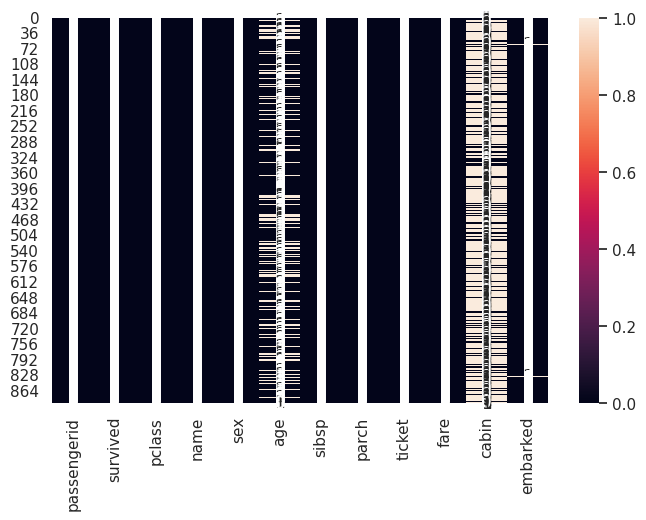

In [ ]:
# glue = sns.load_dataset("titanic-train").pivot(index="Model", columns="Task", values="Score")
# sns.heatmap(glue)

sns.heatmap(df.isna(), annot=True)

❓ **Question:** Are the missing `age` values spread across the whole dataset or concentrated in one place?

✍️ **Your answer:** _..._

### 📝 Exercise 1.4: Create helper columns

Add these columns to `df`. You will use them in the rest of the notebook.

| New column | How to build it |
|---|---|
| `survival` | `survived` mapped to the labels `'Died'` / `'Survived'` (easier to read in legends) |
| `class` | `pclass` mapped to `'First'`, `'Second'`, `'Third'` |
| `port` | `embarked` mapped to `'Cherbourg'`, `'Queenstown'`, `'Southampton'` |
| `family_size` | `sibsp + parch + 1` (the passenger plus their relatives) |
| `age_group` | `age` binned into `Child (0-12)`, `Teen (13-19)`, `Adult (20-39)`, `Middle-aged (40-59)`, `Senior (60+)` |
| `title` | The title from `name`, e.g. `"Braund, Mr. Owen Harris"` → `Mr` |
| `deck` | The first letter of `cabin` (`'Unknown'` when missing) |

<details>
<summary>💡 Hint</summary>

`map()`, `pd.cut()`, `str.extract()`, `str[0]`

</details>

In [2]:
# ✏️ Your code here
df['survived_str'] = df['survived'].replace({1: 'Survived', 0: 'Died'})


df['class'] = df['pclass'].replace({1: 'First', 2: 'Second', 3: 'Third'})

df['port'] = df['embarked'].replace({'C': 'Cherbourg', 'Q': 'Queenstown', 'S': 'Southampton'})

df['family_size'] = df['sibsp'] + df['parch'] + 1

df['age_group'] = pd.cut(df['age'], bins=[0, 12, 19, 39, 59, df['age'].max()],
                         labels=['Child', 'Teen', 'Adult', 'Middle-aged', 'Senior'])

df['title'] = df['name'].apply(lambda name: name.split(',')[1].split('.')[0].strip())

df['deck'] = df['cabin'].apply(lambda n: 'Unknown' if pd.isnull(n) else n)


df.head()

,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,survived_str,class,port,family_size,age_group,title,deck
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Died,Third,Southampton,2,Adult,Mr,Unknown
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Survived,First,Cherbourg,2,Adult,Mrs,C85
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Survived,Third,Southampton,1,Adult,Miss,Unknown
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Survived,First,Southampton,2,Adult,Mrs,C123
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Died,Third,Southampton,1,Adult,Mr,Unknown


❓ **Question:** How many distinct titles did you find? Which four titles are the most common?

✍️ **Your answer:** _..._

<a id="ch2"></a>
# 📊 Chapter 2: Univariate Analysis

### 🎯 Goal:
Explore **one variable at a time**: its shape, spread, outliers and most common values.

**Charts to practice:** histogram, density plot, box plot, bar plot, pie chart.

## 📈 Histogram

### 📝 Exercise 2.1: Age distribution: the effect of bin size

Create **one figure with 3 subplots** showing a histogram of `age` with **5, 20 and 60 bins**.

<details>
<summary>💡 Hint</summary>

`plt.subplots()`

</details>

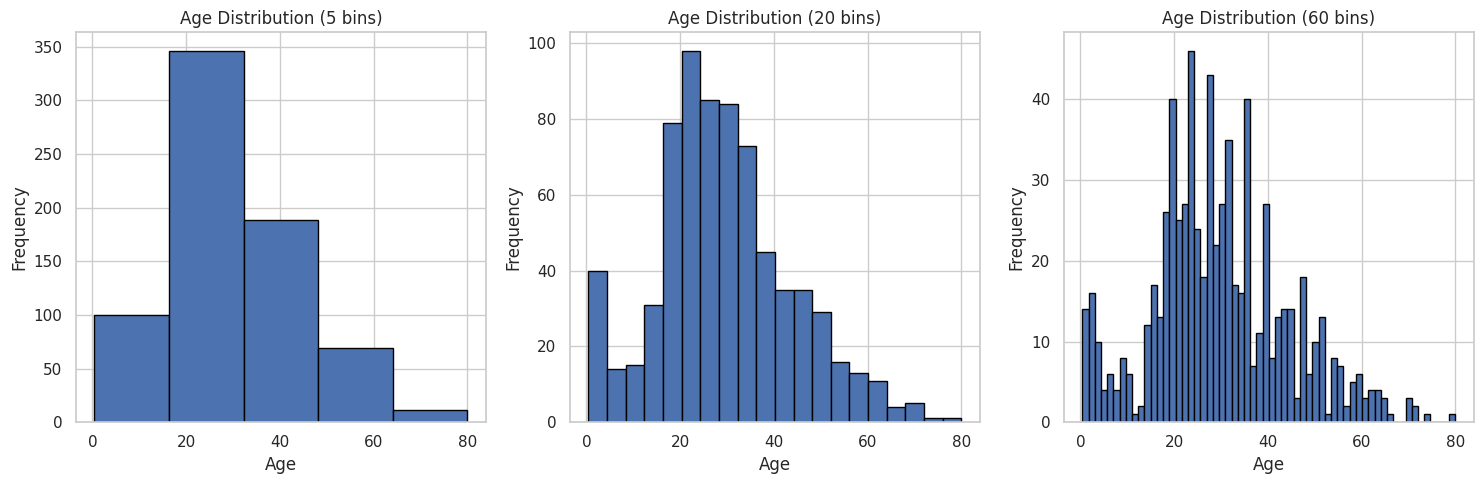

In [ ]:

# Exercise 2.1: Age distribution — effect of bin size

# Create 3 subplots in one figure
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Different bin sizes
bins_list = [5, 20, 60]

for ax, bins in zip(axes, bins_list):
    ax.hist(df['age'].dropna(), bins=bins, edgecolor='black')
    ax.set_title(f'Age Distribution ({bins} bins)')
    ax.set_xlabel('Age')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()


❓ **Question:** Which bin count tells the clearest story? What do you lose with too few bins, and what goes wrong with too many? Is there a visible bump for young children?

✍️ **Your answer:** _..._

### 📝 Exercise 2.2: Fare distribution: raw vs log scale

Plot the distribution of `fare` side by side on the **raw scale** and on a **log scale**.

<details>
<summary>💡 Hint</summary>

Check the minimum fare first.

</details>

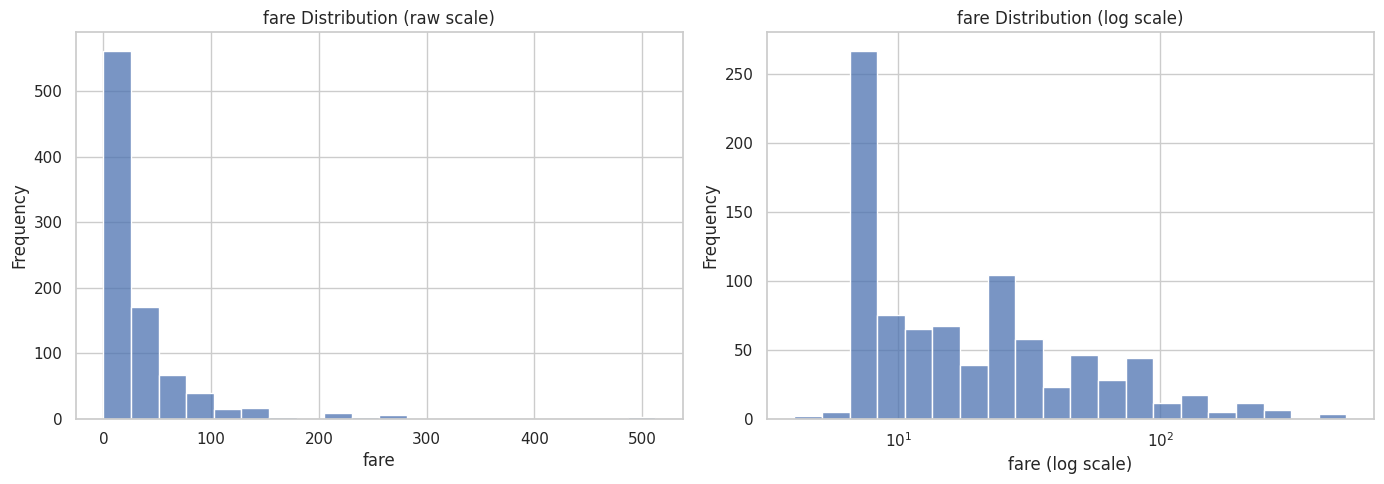

In [ ]:
# ✏️ Your code here
# Seaborn histogram for Sales: raw scale vs log scale
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['fare'], bins=20, ax=axes[0])
axes[0].set(title="fare Distribution (raw scale)", xlabel="fare", ylabel="Frequency")

sns.histplot(df['fare'], bins=20, log_scale=True, ax=axes[1])
axes[1].set(title="fare Distribution (log scale)", xlabel="fare (log scale)", ylabel="Frequency")

plt.tight_layout()
plt.show()

❓ **Question:** Describe the shape of `fare`. What is the median fare, and what is the maximum? Why does the log scale make the chart easier to read?

✍️ **Your answer:** _..._

### 📝 Exercise 2.3: Family size with Plotly

Draw a **Plotly histogram** of `family_size`.

In [ ]:
# ✏️ Your code here
# Create a basic histogram
fig = px.histogram(df, x="family_size", title="family size Distribution")
fig.show()

❓ **Question:** What is the most common family size? Roughly what share of passengers travelled alone?

✍️ **Your answer:** _..._

---



## 🛣️ Density Plot

### 📝 Exercise 2.4: Age density

Draw a **KDE plot** of `age` with Seaborn (`fill=True`). Then draw a Plotly histogram of `age` with `histnorm='density'`.

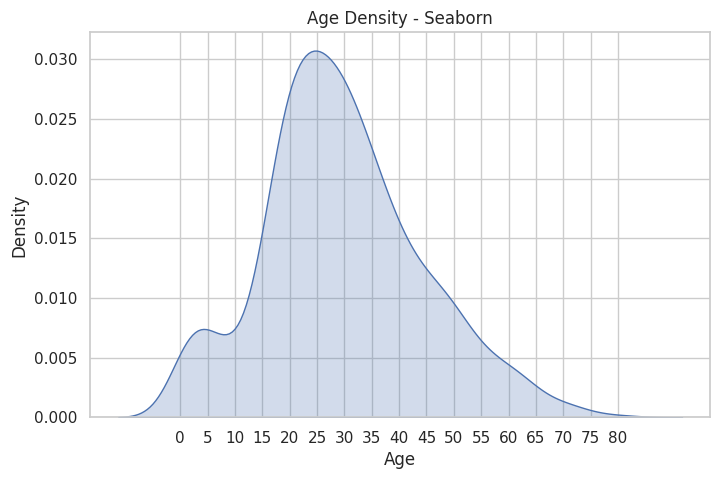

In [ ]:
# ✏️ Your code here
fig, ax = plt.subplots()
sns.kdeplot(df['age'], fill=True, ax=ax)
ax.set(title="Age Density - Seaborn", xlabel="Age")
ax.set_xticks(np.arange(0, 81, 5))
plt.show()

❓ **Question:** Is the age distribution unimodal or does it have more than one peak? Where are the peaks?

✍️ **Your answer:** _..._

## 📦 Box Plot

### 📝 Exercise 2.5: Outliers in age and fare

Draw a horizontal **Seaborn box plot** of `age`, and a **Plotly box plot** of `fare` (try `log_x=True`).

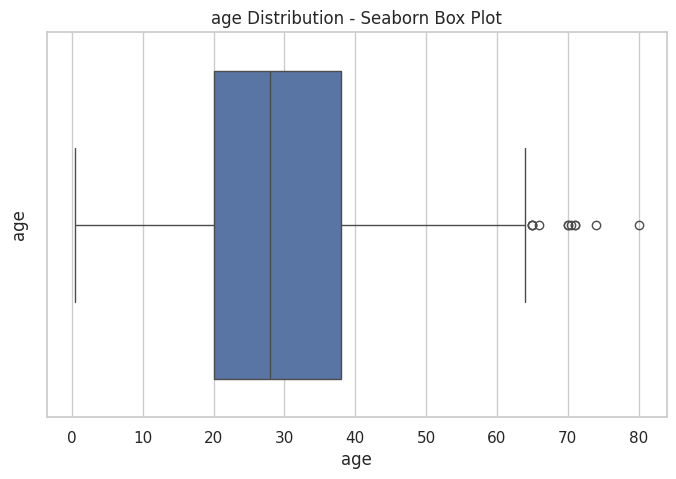

In [ ]:
# ✏️ Your code here

fig, ax = plt.subplots()
sns.boxplot(x=df['age'], ax=ax)
ax.set(title="age Distribution - Seaborn Box Plot", ylabel="age")
plt.show()

❓ **Question:** Which variable has more outliers? Roughly how expensive were the most extreme fares compared with the median?

✍️ **Your answer:** _..._

## 📊 Bar Plot

### 📝 Exercise 2.6: Who was on board?

Create **count plots** for `class`, `sex` and `port`, each with its bars **sorted from most to least frequent**.
Put all three in **one figure with 3 subplots**.

<details>
<summary>💡 Hint</summary>

`order=`

</details>

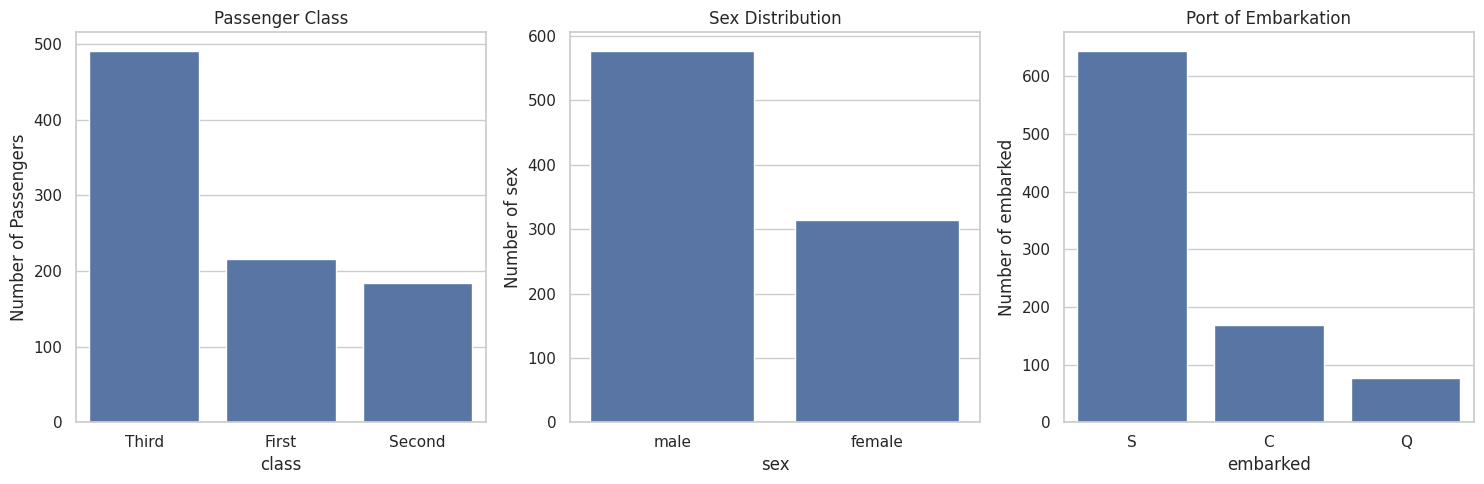

In [ ]:

# Exercise 2.6: Who was on board?

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.countplot(data=df, x='class', order=df['class'].value_counts().index, ax=axes[0])

axes[0].set_title('Passenger Class')
axes[0].set_xlabel('class')
axes[0].set_ylabel('Number of Passengers')

sns.countplot(data=df, x='sex', order=df['sex'].value_counts().index, ax=axes[1])

axes[1].set_title('Sex Distribution')
axes[1].set_xlabel('sex')
axes[1].set_ylabel('Number of sex')

sns.countplot(data=df, x='embarked', order=df['embarked'].value_counts().index, ax=axes[2])

axes[2].set_title('Port of Embarkation')
axes[2].set_xlabel('embarked')
axes[2].set_ylabel('Number of embarked')

# columns = ['class', 'sex', 'embarked']
# titles = ['Passenger Class', 'Sex Distribution', 'Port of Embarkation']

# for ax, col, title in zip(axes, columns, titles):
#     order = df[col].value_counts().index

#     sns.countplot(
#         data=df,
#         x=col,
#         order=order,
#         ax=ax
#     )

#     ax.set_title(title)
#     ax.set_xlabel(col.capitalize())
#     ax.set_ylabel('Number of Passengers')

plt.tight_layout()
plt.show()


❓ **Question:** Which class, sex and port were most common among passengers?

✍️ **Your answer:** _..._

### 📝 Exercise 2.7: Most common titles

Show the **top 6 titles** as a **Plotly bar chart** (sorted).

<details>
<summary>💡 Hint</summary>

`value_counts()`

</details>

In [ ]:
# ✏️ Your code here

top_6_titles = df['title'].value_counts().head(6).sort_values(ascending=False)

fig = px.bar(x=top_6_titles.index, y=top_6_titles.values, title='Top 6 Most Common Titles')
fig.show()

## 🥧 Pie Chart

### 📝 Exercise 2.8: Overall survival

Show the share of passengers who **died vs survived** as a Matplotlib pie chart with percentages, and then as a Plotly pie chart.

<details>
<summary>💡 Hint</summary>

`autopct`

</details>

In [ ]:
# ✏️ Your code here
# labels = ['survived', 'died']
# sizes = [(df['survived'].sum() / len(df)) * 100, ((len(df) - df['survived'].sum())  / len(df)) * 100]

# plt.pie(sizes, labels=labels)

# plt.show()


# ###############################################

table = df["survived_str"].value_counts().reset_index()
table.columns = ["survived", "count"]

table

fig = px.pie(
    table,
    names="survived",
    values="count",
    title="Overall Passenger Survival",
    hole=0  # Standard pie chart
)

fig.update_traces(textinfo="label+percent")

fig.show()

❓ **Question:** What percentage of passengers survived? Is a pie chart a good choice here? Would it be a good choice for `title`? Why or why not?

✍️ **Your answer:** _..._

<a id="ch3"></a>
# 🔗 Chapter 3: Bivariate Analysis

### 🎯 Goal:
Explore relationships between **two variables**, and in particular how each variable relates to **survival**.

> 💡 **Key trick:** `survived` is 0/1, so **its mean is the survival rate**. `df.groupby('sex')['survived'].mean()` gives the share of survivors in each group, and `sns.barplot(..., y='survived')` plots it directly.

## 🎯 Categorical vs Numerical: Survival Rates

### 📝 Exercise 3.1: Survival rate by sex and by class

In **one figure with 2 subplots**, plot the **survival rate**:
- by `sex`
- by `class` (in the order First, Second, Third)

Label the y-axis as *Survival rate* and keep it between 0 and 1.

<details>
<summary>💡 Hint</summary>

`sns.barplot()`, `set_ylim()`

</details>

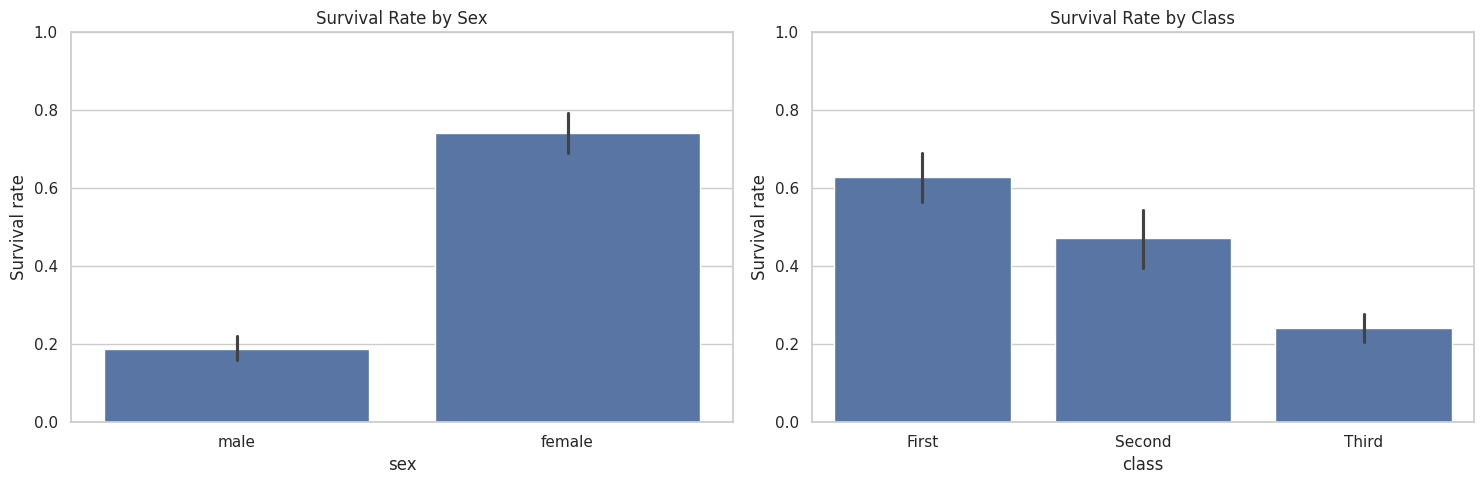

In [ ]:
# ✏️ Your code here
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Survival rate by sex
sns.barplot(data=df, x='sex', y='survived', ax=axes[0])
axes[0].set_title('Survival Rate by Sex')
axes[0].set_ylabel('Survival rate')
axes[0].set_ylim(0, 1)


# 2. Survival rate by class
sns.barplot(
    data=df,
    x='class',
    y='survived',
    order=['First', 'Second', 'Third'],
    ax=axes[1]
)
axes[1].set_title('Survival Rate by Class')
axes[1].set_ylabel('Survival rate')
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

❓ **Question:** What was the survival rate of women vs men? Of First vs Third class? Which of the two factors looks stronger?

✍️ **Your answer:** _..._

### 📝 Exercise 3.2: Survival rate by port and by age group

Plot the survival rate by `port` and by `age_group` (keep the age groups in their natural order, **do not** sort them).

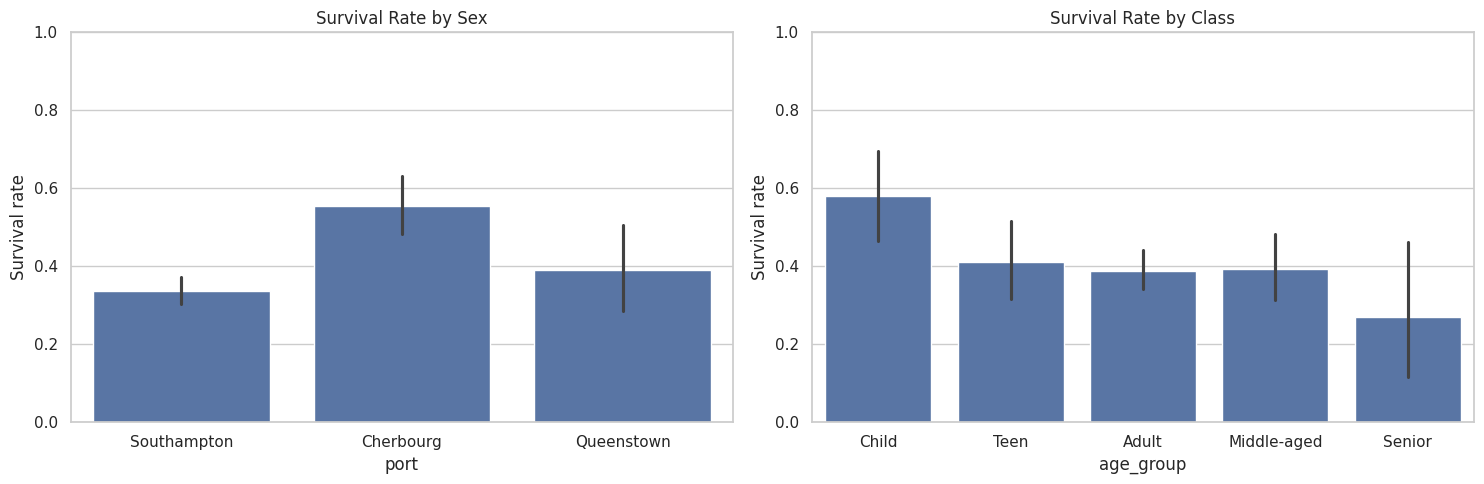

In [ ]:
# ✏️ Your code here
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Survival rate by sex
sns.barplot(data=df, x='port', y='survived', ax=axes[0])
axes[0].set_title('Survival Rate by Sex')
axes[0].set_ylabel('Survival rate')
axes[0].set_ylim(0, 1)


# 2. Survival rate by class
sns.barplot(
    data=df,
    x='age_group',
    y='survived',
    ax=axes[1]
)
axes[1].set_title('Survival Rate by Class')
axes[1].set_ylabel('Survival rate')
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

❓ **Question:** Which port had the highest survival rate? Which age group had the highest? Can you think of a reason the port might matter?

✍️ **Your answer:** _..._

### 📝 Exercise 3.3: Age by survival

Compare the distribution of `age` for those who died and those who survived using **a box plot and a violin plot** side by side.

Text(0, 0.5, 'Survival rate')

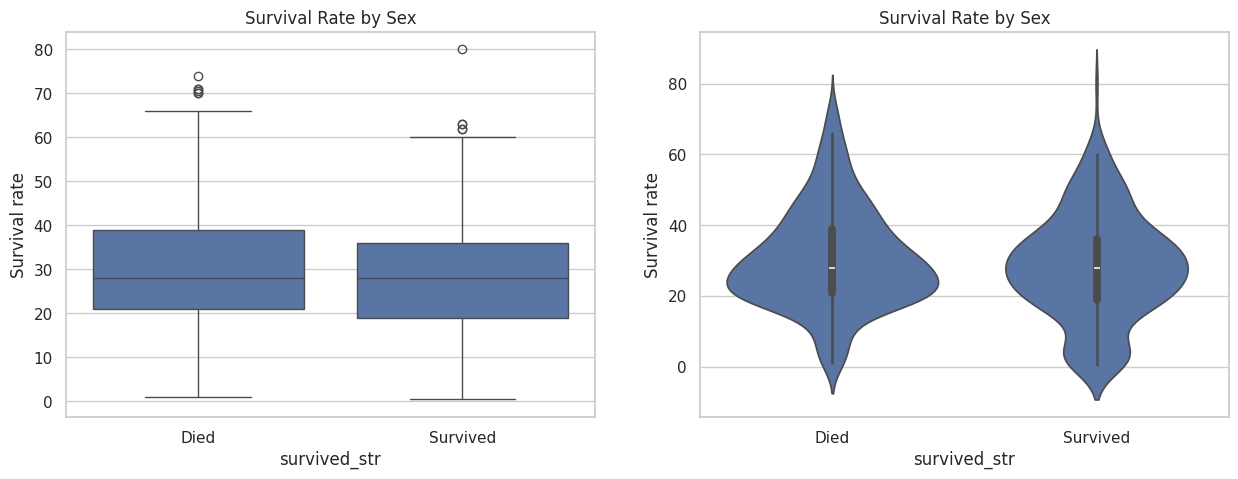

In [ ]:
# ✏️ Your code here
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=df, x='survived_str', y='age', ax=axes[0])
axes[0].set_title('Survival Rate by Sex')
axes[0].set_ylabel('Survival rate')

sns.violinplot(data=df, x='survived_str', y='age', ax=axes[1])
axes[1].set_title('Survival Rate by Sex')
axes[1].set_ylabel('Survival rate')


❓ **Question:** Do the medians differ a lot? Where in the age range do the two violins differ most?

✍️ **Your answer:** _..._

### 📝 Exercise 3.4: Fare by class with Plotly

Draw a **Plotly box plot** of `fare` by `class`, colored by `class`. Try it with and without `log_y=True`.

In [ ]:
# # ✏️ Your code here
# # ✏️ Your code here
# fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# sns.boxplot(data=df, x='class', y='fare', ax=axes[0])
# axes[0].set_title('Survival Rate by Sex')
# axes[0].set_ylabel('Survival rate')

# sns.boxplot(data=df, x='class', y='fare', ax=axes[1])
# axes[1].set_title('Survival Rate by Sex')
# axes[1].set_ylabel('Survival rate')


# fig = px.box(
#     df,
#     x="class",
#     y="fare",
#     title="Overall Passenger Survival",
# )
fig = px.box(
    df,
    x="class",
    y="fare",
    title="Overall Passenger Survival",
    log_y=True
)


fig.show()

❓ **Question:** How much higher is the median First-class fare compared with Third? Which class has the widest spread?

✍️ **Your answer:** _..._

## 📌 Scatter Plot

### 📝 Exercise 3.5: Age vs Fare

Draw a **Seaborn scatter plot** of `age` (x) against `fare` (y). Use `alpha` to reduce overplotting. Then draw the same chart with **Plotly**, colored by `survival`.

In [6]:
# ✏️ Your code here
# sns.scatterplot(data=df, x="age", y="fare", alpha=0.5)

# plt.show()

# ------------------
fig = px.scatter(df, 'age', 'fare', opacity=0.5, title="Age vs Fare - Seaborn scatter")

# To save it
from pathlib import Path

# Create figures folder
Path('figures').mkdir(exist_ok=True)

# Save dashboard as PNG
# fig.savefig(
#     'figures/Age_vs_Fare_scatter.png',
#     dpi=150,
#     bbox_inches='tight'
# )
fig.write_html('figures/Age_vs_Fare_scatter.html')

from google.colab import files
files.download('figures/Age_vs_Fare_scatter.html')

fig.show()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

❓ **Question:** Is there a clear linear relationship between age and fare? In the Plotly chart, where are the survivors concentrated?

✍️ **Your answer:** _..._

## 📈 Line Plot

### 📝 Exercise 3.6: Survival rate by family size

There is no time column in this dataset, but `family_size` is an **ordered** numeric variable, so a line plot can show a trend.

1. Compute the survival rate **and the number of passengers** for each `family_size`.
2. Plot the survival rate as a line with markers.

<details>
<summary>💡 Hint</summary>

`groupby()`, `agg()`

</details>

In [ ]:
# survival_rate = df.groupby("family_size")['survived'].sum()
# survival_rate

,survived
family_size,
1,163
2,89
3,59
4,21
5,3
6,3
7,4
8,0
11,0


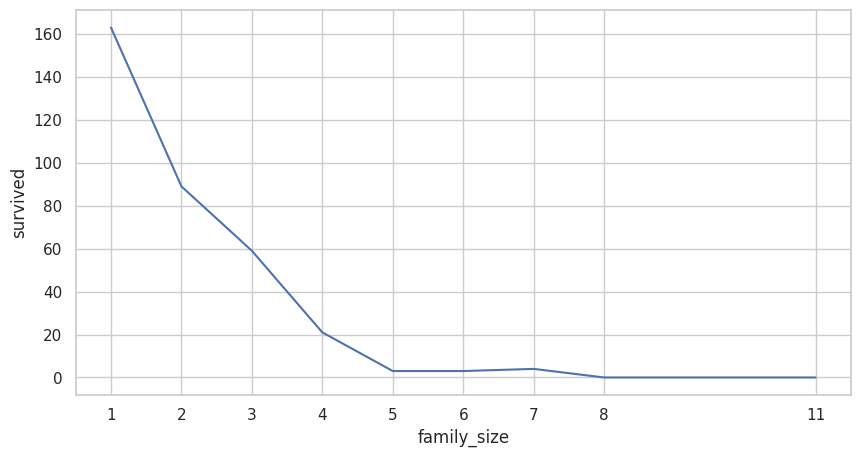

In [ ]:
# ✏️ Your code here
survival_rate = df.groupby("family_size")['survived'].sum()
# survival_rate

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=survival_rate)
ax.set_xticks(survival_rate.index)
plt.show()

             survival_rate
family_size               
1                30.353818
2                55.279503
3                57.843137
4                72.413793
5                20.000000
6                13.636364
7                33.333333
8                 0.000000
11                0.000000


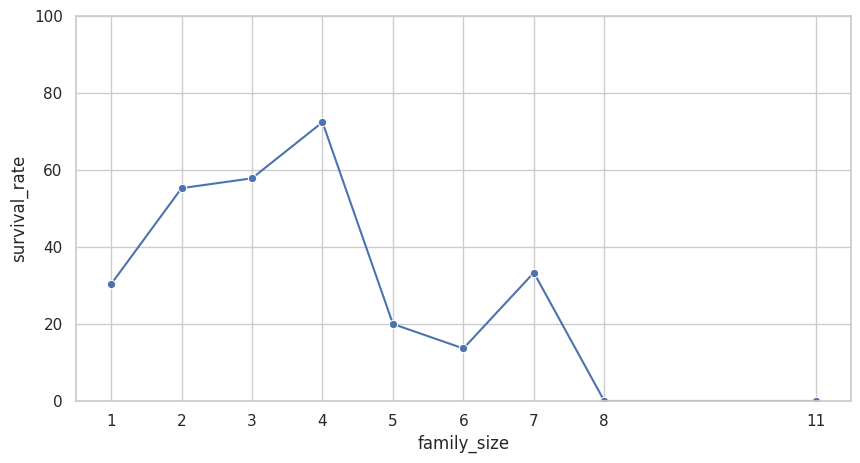

In [ ]:
# 1. Compute survival rate and passenger count for each family size
family_stats = df.groupby("family_size")["survived"].agg(
    survival_rate="mean",
    # passenger_count="count"
)

family_stats["survival_rate"] *= 100

print(family_stats)

# 2. Plot survival rate as a line with markers
fig, ax = plt.subplots(figsize=(10, 5))

sns.lineplot(
    data=family_stats,
    x=family_stats.index,
    y="survival_rate",
    marker="o",
    ax=ax
)

ax.set_xticks(family_stats.index)
ax.set_ylim(0, 100)

plt.show()

❓ **Question:** Which family sizes had the best chance of survival? What happens to the rate for very large families? How many passengers are behind the points for sizes 7, 8 and 11, and how much should you trust them?

✍️ **Your answer:** _..._

## 🔥 Correlation Heatmap

:### 📝 Exercise 3.7: Correlation heatmap

1. Add a numeric column `is_female` (1 for female, 0 for male).
2. Draw a **correlation heatmap** of `survived`, `pclass`, `is_female`, `age`, `sibsp`, `parch`, `fare`, `family_size`.
3. Fix the color range to `[-1, 1]` and center it at 0, as in the tutorial. Draw it with both Seaborn and Plotly.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

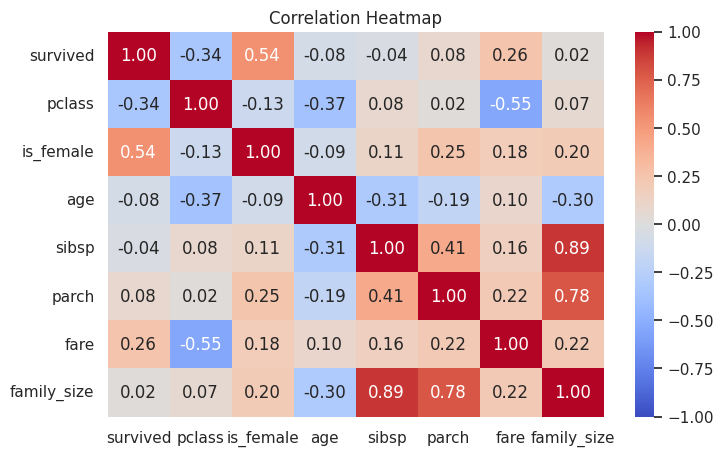

In [8]:
# ✏️ Your code here
df["is_female"] = (df["sex"] == "female").astype(int)

corr = df[['survived', 'pclass', 'is_female', 'age', 'sibsp', 'parch', 'fare', 'family_size']].corr()

fig, ax = plt.subplots()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title("Correlation Heatmap")

# To save it
from pathlib import Path

# Create figures folder
Path('figures').mkdir(exist_ok=True)

# Save dashboard as PNG
fig.savefig(
    'figures/Correlation_Heatmap.png',
    dpi=150,
    bbox_inches='tight'
)

from google.colab import files
files.download('figures/Correlation_Heatmap.png')

plt.show()


❓ **Question:** Which variable has the strongest correlation with `survived`? Why is the correlation between `pclass` and `survived` negative even though class clearly matters? Which pair of variables is highly correlated *by construction*?

✍️ **Your answer:** _..._

## 🎯 Strip & Swarm Plots

### 📝 Exercise 3.8: Individual passengers

1. Draw a **strip plot** of `age` by `class`, colored by `survival`.
2. Draw a **swarm plot** of `fare` by `class` (use a sample of about 300 passengers and `log_scale=True`).

<details>
<summary>💡 Hint</summary>

`dodge`, `sample()`

</details>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

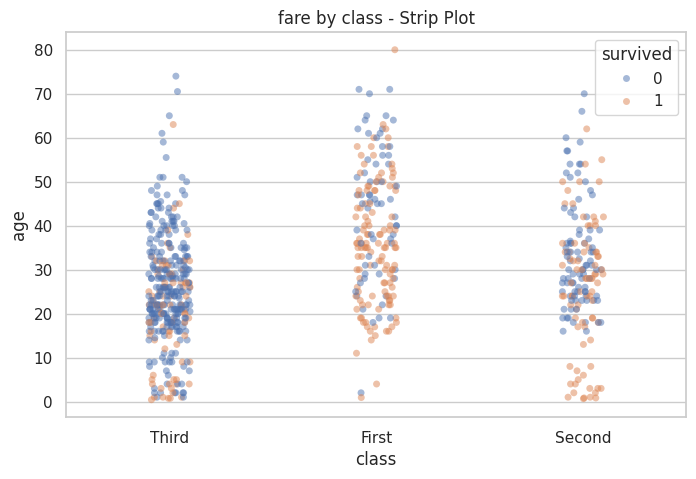

In [10]:
# ✏️ Your code here
fig, ax = plt.subplots()
sns.stripplot(data=df, x='class', y='age', hue="survived", alpha=0.5, ax=ax)
ax.set_title("fare by class - Strip Plot")

# To save it
from pathlib import Path

# Create figures folder
Path('figures').mkdir(exist_ok=True)

# Save dashboard as PNG
fig.savefig(
    'figures/fare_by_class_Strip_Plot.png',
    dpi=150,
    bbox_inches='tight'
)

from google.colab import files
files.download('figures/fare_by_class_Strip_Plot.png')

plt.show()

❓ **Question:** In which class do survivors look most common among children? What does the swarm plot show that a box plot hides?

✍️ **Your answer:** _..._

## 🧩 Categorical vs Categorical

### 📝 Exercise 3.9: Survival counts by class

Draw a **count plot** of `class` with `hue='survival'`.

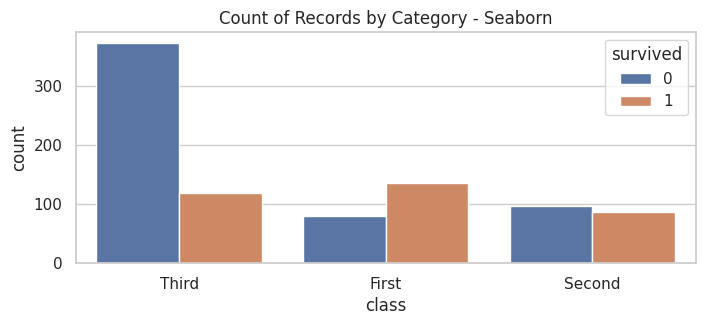

In [ ]:
# ✏️ Your code here
fig, ax = plt.subplots(figsize=(8, 3))
#  order=df['class'].value_counts().index,
sns.countplot(data=df, x='class', hue='survived', ax=ax)
ax.set_title("Count of Records by Category - Seaborn")
plt.show()

❓ **Question:** In which class did the **number** of deaths far exceed the number of survivors? In which class did more people survive than die?

✍️ **Your answer:** _..._

### 📝 Exercise 3.10: Crosstab heatmap

Build a `pd.crosstab` of `sex` × `class` (counts) and show it as an annotated heatmap.

<details>
<summary>💡 Hint</summary>

`fmt`

</details>

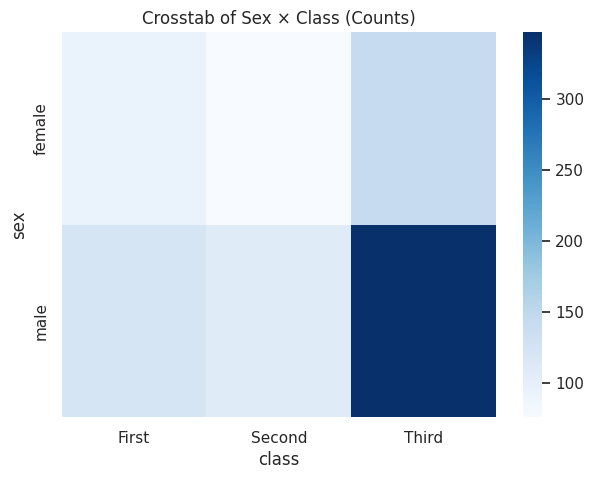

In [ ]:
# ✏️ Your code here
# 1. Generate the cross-tabulation table of counts
crosstab_df = pd.crosstab(df['sex'], df['class'])

plt.figure(figsize=(7, 5))
sns.heatmap(
    crosstab_df,
    # annot=True,  # Display numerical values inside cells
    # fmt='d',  # Format numbers as integers (counts)
    cmap='Blues',  # Color palette
    # cbar=True,  # Include colorbar
)

plt.title('Crosstab of Sex × Class (Counts)')
# plt.xlabel('Class')
# plt.ylabel('Sex')
# plt.tight_layout()
plt.show()

### 📝 Exercise 3.11: Grouped bar with Plotly

Count passengers by `port` and `survival` and draw a **grouped Plotly bar chart** (`barmode='group'`).

In [ ]:
# ✏️ Your code here
grouped_df = (
    df.groupby(['embarked', 'survived']).size().reset_index(name='count')
)
# grouped_df

fig = px.bar(
    grouped_df,
    x='embarked',
    y='count',
    color='survived',
    barmode='group',  # Sets bars side-by-side
    # title='Passenger Count by Embarkation Port and Survival',
    # labels={
    #     'embarked': 'Embarkation Port',
    #     'count': 'Passenger Count',
    #     'survived': 'Status',
    # },
    # color_discrete_map={'Died': '#EF553B', 'Survived': '#00CC96'},
)

fig.show()

### 📝 Exercise 3.12: Who boarded where?

Show the **class mix of each port** with a crosstab normalized by row (`normalize='index'`) and draw it as a heatmap with percentages.

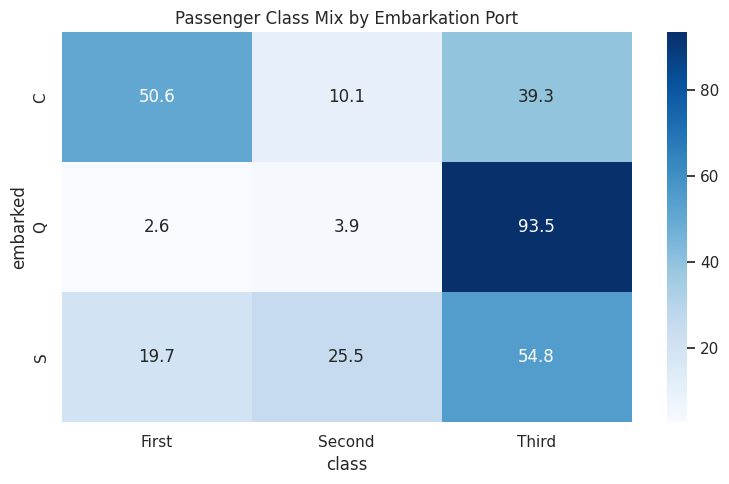

In [ ]:
# ✏️ Your code here
ct_pct = pd.crosstab(df['embarked'], df['class'], normalize='index') * 100
# ct_pct

plt.figure(figsize=(8, 5))
sns.heatmap(
    ct_pct,
    annot=True,
    fmt='.1f',
    cmap='Blues',
)

plt.title('Passenger Class Mix by Embarkation Port')
plt.tight_layout()
plt.show()

❓ **Question:** Does this explain your answer about ports in Exercise 3.2?

✍️ **Your answer:** _..._

<a id="ch4"></a>
# 🧩 Chapter 4: Multivariate Analysis

### 🎯 Goal:
Look at **three or more variables at once** to find interactions, for example: *does the effect of sex on survival depend on class?*

## 🎨 Colored Scatter Plot

### 📝 Exercise 4.1: Age vs Fare, colored by survival, faceted by class

Create a **Plotly scatter** of `age` vs `fare` with `color='survival'` and `facet_col='class'`. Use a log y-axis.

<details>
<summary>💡 Hint</summary>

`category_orders`

</details>

In [ ]:
# ✏️ Your code here
fig = px.scatter(df, x='age', y='fare', color="survived_str", facet_col="class", opacity=0.5)
fig.show()

❓ **Question:** In which class do the survivors and non-survivors look most mixed? In which class is death most dominant?

✍️ **Your answer:** _..._

## 🔁 Pair Plot

### 📝 Exercise 4.2: Pair plot

Draw a **pair plot** of `age`, `fare`, `sibsp`, `parch` with `hue='survival'` and `corner=True`. Add a title with `g.fig.suptitle(...)`.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

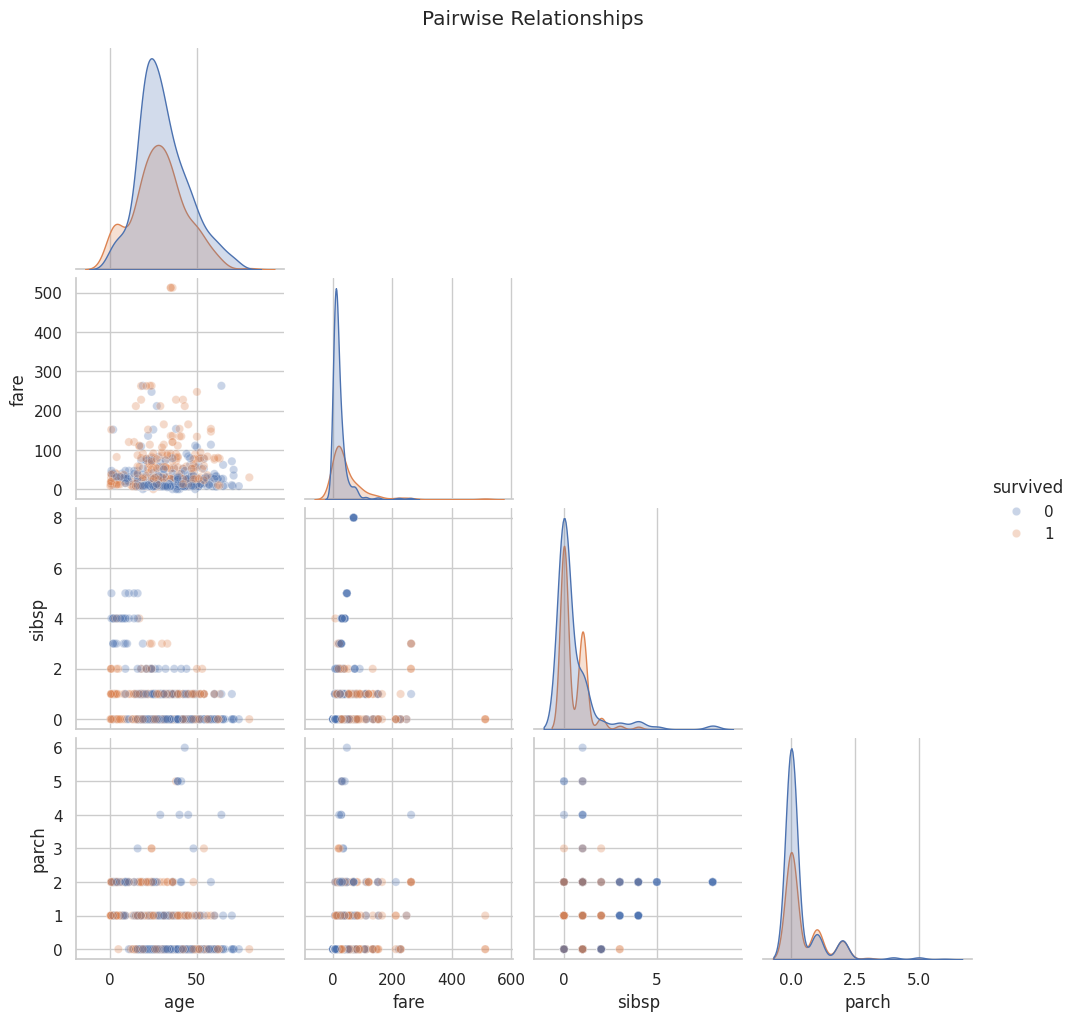

In [11]:
# ✏️ Your code here
g = sns.pairplot(df[['age', 'fare', 'sibsp', 'parch', 'survived']], corner=True, plot_kws={'alpha': 0.3}, hue='survived')
g.fig.suptitle("Pairwise Relationships", y=1.02)

# # To save it
# from pathlib import Path

# # Create figures folder
# Path('figures').mkdir(exist_ok=True)

# # Save dashboard as PNG
# g.savefig(
#     'figures/Pairwise_Relationships.png',
#     dpi=150,
#     bbox_inches='tight'
# )

# from google.colab import files
# files.download('figures/Pairwise_Relationships.png')

plt.show()

❓ **Question:** Which single panel shows the clearest separation between survivors and non-survivors?

✍️ **Your answer:** _..._

## 🧩 Faceted Plot

### 📝 Exercise 4.3: Survival rate by sex within each class

Use `sns.catplot(kind='bar')` (or a `FacetGrid`) to show the **survival rate by sex, with one panel per class**.

<details>
<summary>💡 Hint</summary>

`sns.catplot()`

</details>

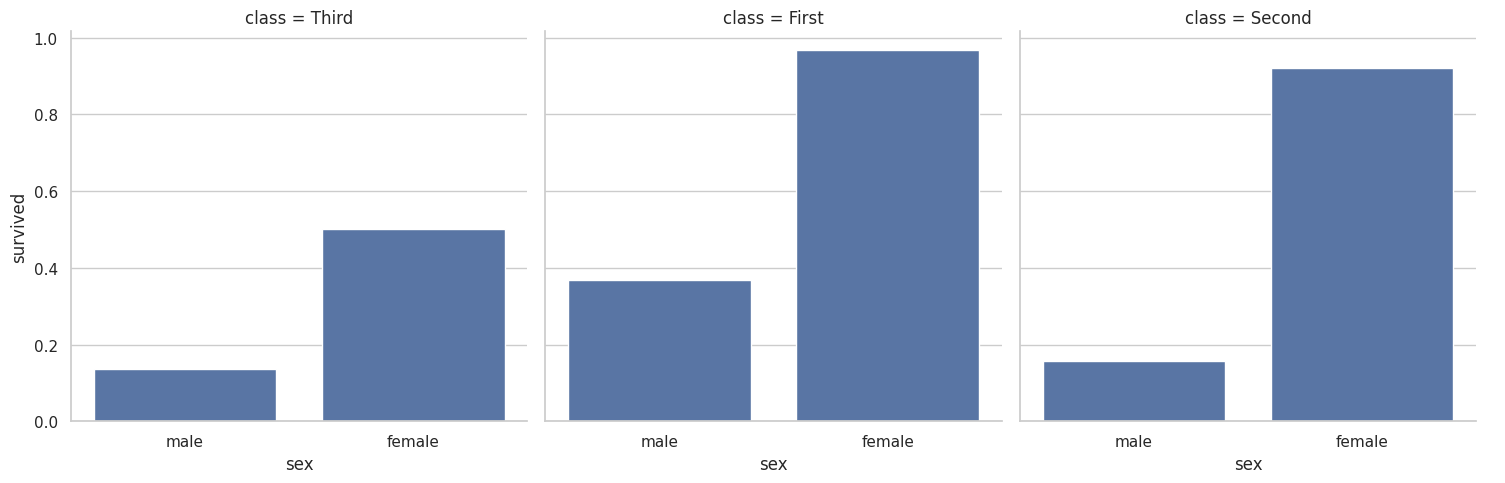

In [ ]:
# ✏️ Your code here
# Using sns.catplot to display survival rate by sex across each class
g = sns.catplot(
    data=df,
    x="sex",
    y="survived",
    col="class",  # Use 'pclass' if your dataset column is named 'pclass'
    kind="bar",
    errorbar=None,  # Set to None to hide confidence intervals (ci=None in older seaborn)
)

# Optional axis labeling and title formatting

plt.show()

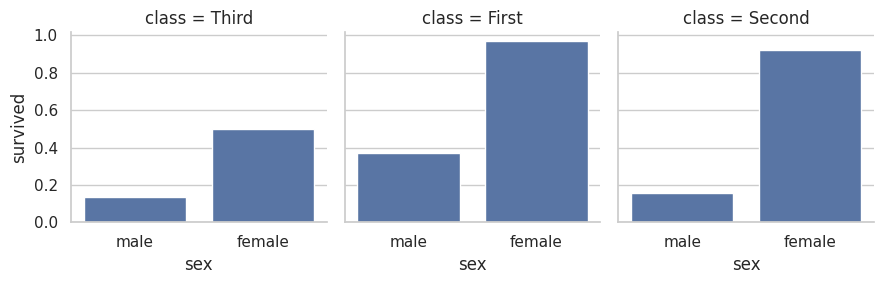

In [ ]:
# Initialize the FacetGrid separated by class columns
g = sns.FacetGrid(df, col="class")

# Map sns.barplot onto the grid
g.map(sns.barplot, "sex", "survived", order=["male", "female"], errorbar=None)

❓ **Question:** What was the survival rate of First-class women? Of Third-class men? Was being female equally protective in every class?

✍️ **Your answer:** _..._

### 📝 Exercise 4.4: Age histograms by class and survival

Use a `FacetGrid` with `row='survival'` and `col='class'` to draw histograms of `age`.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

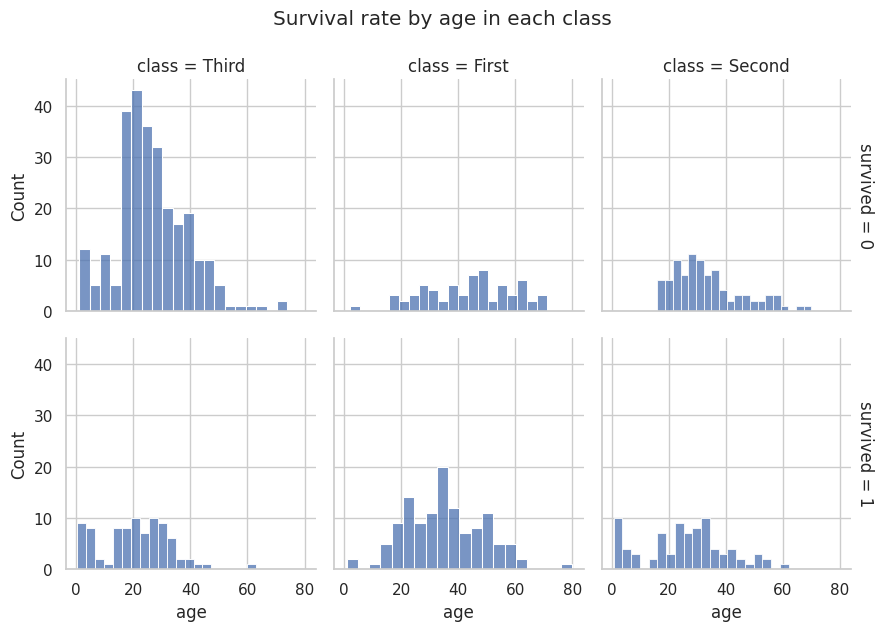

In [36]:
# Initialize the FacetGrid with rows for survival status and columns for passenger class
g = sns.FacetGrid(df, row="survived", col="class", margin_titles=True)

# Map sns.histplot (or plt.hist) to plot age histograms across each subplot
g.map(sns.histplot, "age", bins=20)

# Overall figure title
g.figure.suptitle("Survival rate by age in each class", y=1.05)

# To save it
# from pathlib import Path

# # Create figures folder
# Path('figures').mkdir(exist_ok=True)

# # Save dashboard as PNG
# g.savefig(
#     'figures/Survival_rate_by_age_in_each_class_histplot.png',
#     dpi=150,
#     bbox_inches='tight'
# )

# from google.colab import files
# files.download('figures/Survival_rate_by_age_in_each_class_histplot.png')

❓ **Question:** Where do you see the largest group of children who died?

✍️ **Your answer:** _..._

## 🧯 Category Heatmap

### 📝 Exercise 4.5: Survival rate heatmap

Build a `pivot_table` of the **mean of `survived`** with `sex` as rows and `class` as columns, and show it as an annotated heatmap with Seaborn and Plotly.

Then make a second heatmap with `age_group` as rows and `class` as columns.

<details>
<summary>💡 Hint</summary>

`vmin`, `vmax`, `fmt`

</details>

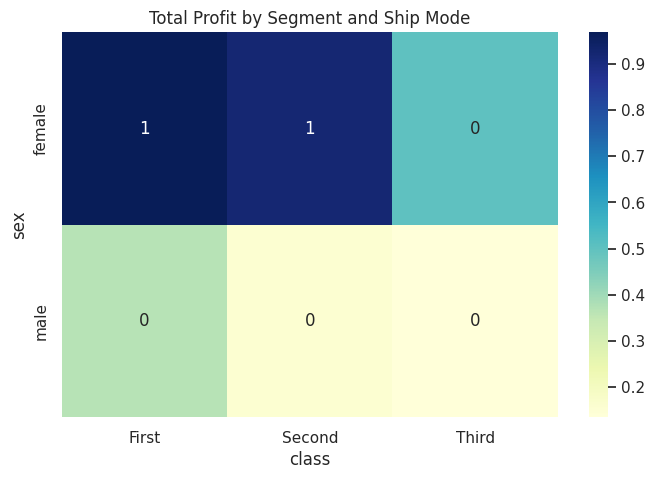

In [ ]:
# ✏️ Your code here
pivot = df.pivot_table(index='sex', columns='class', values='survived', aggfunc='mean')
# All values are positive, so a sequential colormap is the right choice
# (use a diverging map with center=0 when values can be negative)
fig, ax = plt.subplots()
sns.heatmap(pivot, annot=True, fmt=',.0f', cmap='YlGnBu', ax=ax)
ax.set_title("Total Profit by Segment and Ship Mode")
plt.show()

❓ **Question:** Which combination had the highest survival rate, and which had the lowest? Did children in Third class have the same chance as children in First and Second?

✍️ **Your answer:** _..._

## 🌳 Treemap / Sunburst

### 📝 Exercise 4.6: Passenger hierarchy

1. Aggregate the data by `class` and `sex`: count passengers and compute the survival rate.
2. Draw a **treemap** with `path=['class', 'sex']`, box **size** = number of passengers, **color** = survival rate.
3. Bonus: draw the same data as a `px.sunburst`.

<details>
<summary>💡 Hint</summary>

Aggregate first.

</details>

In [28]:
# ✏️ Your code here
new = df.groupby(["class", "sex"])["survived"].agg(passenger_count="count", survival_rate="mean").reset_index()
# new

fig = px.treemap(
    new,
    path=["class", "sex"],
    color="survival_rate",
        color_continuous_scale=[
        [0, "#B91C1C"],    # Dark red
        [0.25, "#F87171"], # Light red
        [0.5, "#FDE68A"],  # Yellow
        [0.75, "#86EFAC"], # Light green
        [1, "#15803D"]     # Dark green
    ],
    range_color=[0, 1],
    title="Titanic Passenger Hierarchy: Survival Rate by Class & Sex",
)

# # To save it
# from pathlib import Path

# # Create figures folder
# Path('figures').mkdir(exist_ok=True)

# # Save dashboard as PNG
# fig.write_image(
#     'figures/Passenger_hierarchy_treemap.png',
#     width=1400,
#     height=1000,
#     scale=2
# )
# fig.write_html('figures/Passenger_hierarchy_treemap.html')

fig.show()


In [17]:
# ✏️ Your code here
new = df.groupby(["class", "sex"])["survived"].agg(passenger_count="count", survival_rate="mean").reset_index()

# Create sunburst chart
fig = px.sunburst(
    new,
    path=["class", "sex"],
    color="survival_rate",
        color_continuous_scale=[
        [0, "#B91C1C"],      # Dark red
        [0.25, "#F87171"],   # Light red
        [0.5, "#FDE68A"],    # Yellow
        [0.75, "#86EFAC"],   # Light green
        [1, "#15803D"]       # Dark green
    ],
    range_color=[0, 1],
    title="Titanic Passenger Hierarchy: Sunburst Chart",
)

# # To save it
# from pathlib import Path

# # Create figures folder
# Path('figures').mkdir(exist_ok=True)


# fig.write_html('figures/Titanic_Passenger_Hierarchy_Sunburst_Chart.html')


fig.show()

❓ **Question:** Which box is both the largest and the darkest (lowest survival)? What does that tell you about where most deaths came from?

✍️ **Your answer:** _..._

## 🫧 Bubble Chart

### 📝 Exercise 4.7: Titles as bubbles

For the titles `Mr`, `Mrs`, `Miss`, `Master` (and optionally group the rest into `'Other'`), compute the **mean age**, **survival rate**, and **count**.

Draw a **bubble chart**: x = mean age, y = survival rate, size = count, color = title. Do it with Plotly, then with Matplotlib.

<details>
<summary>💡 Hint</summary>

`where()`, `isin()`

</details>

In [ ]:
# ✏️ Your code here
# 2. Filter main titles and replace the rest with 'Other' using isin() and where()
main_titles = ['Mr', 'Mrs', 'Miss', 'Master']

# Option A: pandas Series.where(condition, replacement_if_false)
df['title'] = df['title'].where(df['title'].isin(main_titles), 'Other')

# 3. Compute mean age, survival rate, and count per title
summary = df.groupby('title').agg(
    mean_age=('age', 'mean'),
    survival_rate=('survived', 'mean'),
    count=('survived', 'count')
).reset_index()

# print(summary)

fig = px.scatter(
    summary,
    x="mean_age",
    y="survival_rate",
    size="count",  # Controls bubble size (Population)
    color="title",  # Color categories
    # hover_name="country",  # Tooltip title
    # log_x=True,  # Log scale for GDP
    # size_max=60,  # Max bubble diameter in pixels
    # title="Global Life Expectancy vs GDP (2007)",
)

fig.show()

❓ **Question:** *Master* was the title used for boys. How does their survival rate compare with adult men (*Mr*)? What does this tell you about the rule "women and children first"?

✍️ **Your answer:** _..._

## 🏞️ Stacked Bars (Composition)

### 📝 Exercise 4.8: Composition of each class

The tutorial used an area plot to show composition over time. Titanic has no time column, so show composition with **stacked bars** instead:

1. A **100% stacked bar** of `survival` within each `class`.
2. A **stacked bar** of `age_group` counts within each `class`.

<details>
<summary>💡 Hint</summary>

`normalize`, `stacked`

</details>

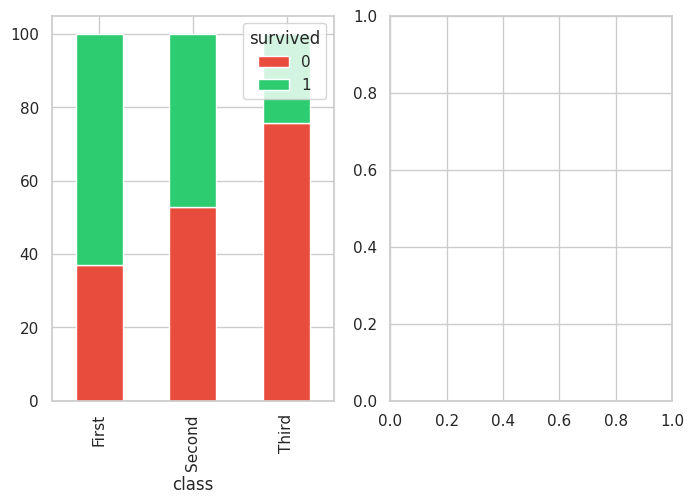

In [15]:
# ✏️ Your code here
# Create cross-tabulation normalized by class (index)
survived_pct = pd.crosstab(df['class'], df['survived'], normalize='index') * 100
# survived_pct
# Plot 100% stacked bar

fig, ax = plt.subplots(1, 2, figsize=(8, 5))
ax[0] = survived_pct.plot(kind='bar', stacked=True, color=['#e74c3c', '#2ecc71'], ax=ax[0])

# plt.tight_layout()
plt.show()

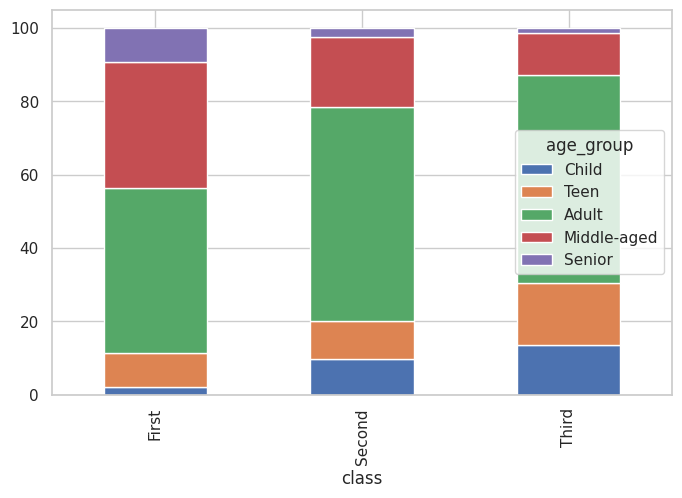

In [ ]:
# ✏️ Your code here
survived_pct = pd.crosstab(df['class'], df['age_group'], normalize='index') * 100
survived_pct
# Plot 100% stacked bar
ax1 = survived_pct.plot(kind='bar', stacked=True, figsize=(8, 5))

# plt.tight_layout()
plt.show()

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

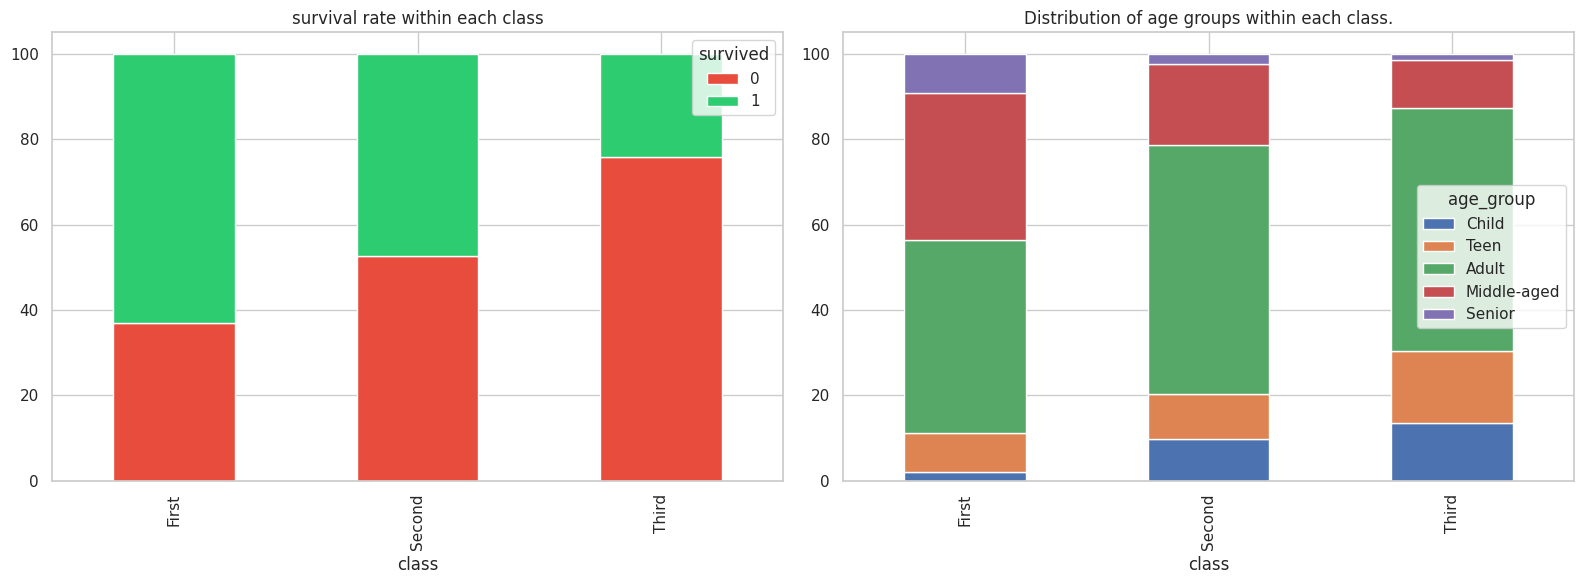

In [27]:


fig, ax = plt.subplots(1, 2, figsize=(16, 6))

survived_pct = pd.crosstab(df['class'], df['survived'], normalize='index') * 100
ax[0] = survived_pct.plot(kind='bar', stacked=True, color=['#e74c3c', '#2ecc71'], ax=ax[0])
ax[0].set_title('survival rate within each class')

age_dist = pd.crosstab(df['class'], df['age_group'], normalize='index') * 100
ax[1] = age_dist.plot(kind='bar', stacked=True, ax=ax[1])
ax[1].set_title('Distribution of age groups within each class.')

# To save it
from pathlib import Path

# Create figures folder
Path('figures').mkdir(exist_ok=True)

# Save dashboard as PNG
plt.savefig(
    'figures/stacked_bars.png',
    dpi=150,
    bbox_inches='tight'
)

from google.colab import files
files.download('figures/stacked_bars.png')

plt.tight_layout()
plt.show()

❓ **Question:** Which class had the largest share of children? How does that relate to the result about children in Exercise 4.5?

✍️ **Your answer:** _..._

## 🧱 Subplots

### 📝 Exercise 4.9: Mini dashboard

Build a **2×2 subplot figure** (`figsize=(14, 10)`) that summarizes the dataset:
- top-left: survival rate by sex
- top-right: survival rate by class
- bottom-left: age distribution by survival (overlaid histograms or KDE)
- bottom-right: survival-rate heatmap of sex × class

Add an overall title with `fig.suptitle(...)` and call `plt.tight_layout()`.

<details>
<summary>💡 Hint</summary>

`axes[row, col]`

</details>

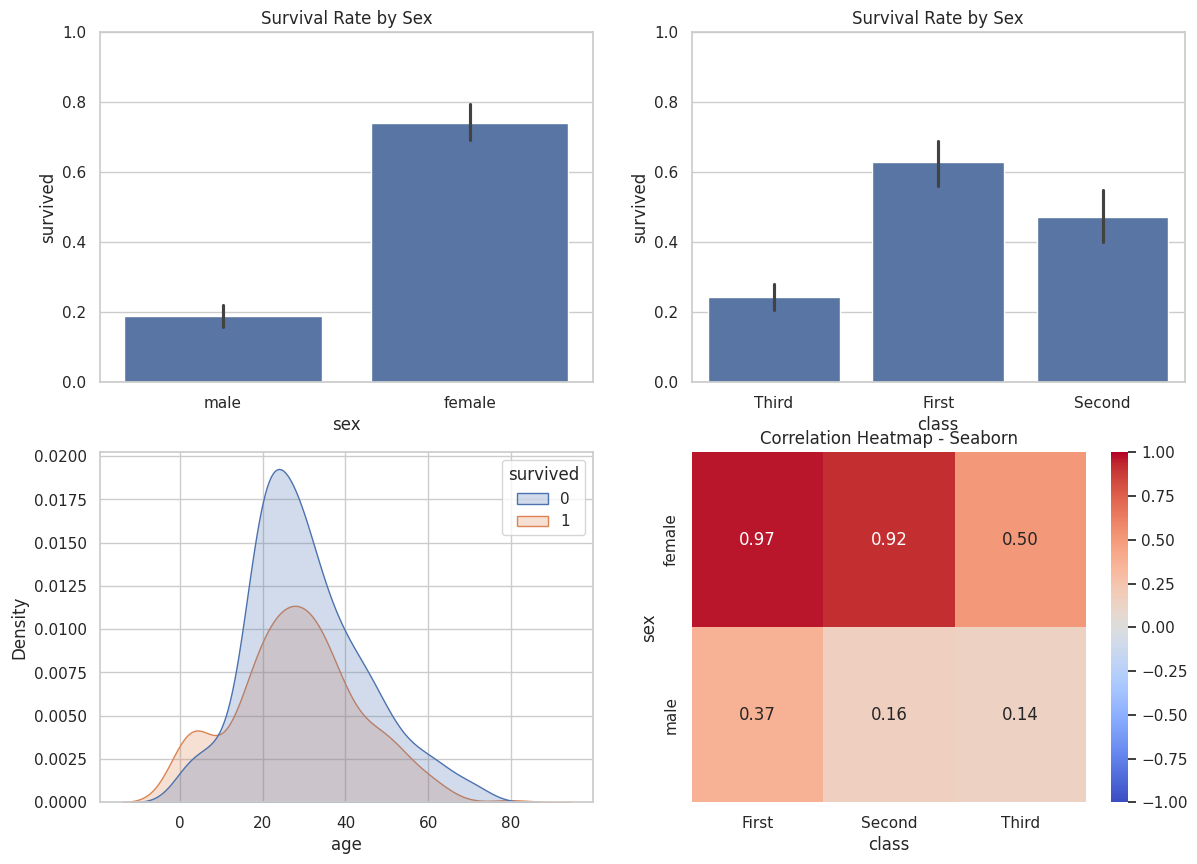

In [37]:
# ✏️ Your code here
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# top-left
sns.barplot(data=df, x="sex", y="survived", ax=axes[0, 0])
axes[0, 0].set_title('Survival Rate by Sex')
axes[0, 0].set_ylim(0, 1)

# top-right
sns.barplot(data=df, x="class", y="survived", ax=axes[0, 1])
axes[0, 1].set_title('Survival Rate by Sex')
axes[0, 1].set_ylim(0, 1)

# bottom-left
sns.kdeplot(data=df, x='age', hue='survived', fill=True, ax=axes[1, 0])

# bottom-right
pivot = df.pivot_table(index='sex', columns='class', values='survived', aggfunc='mean')
sns.heatmap(pivot, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, center=0, ax=axes[1, 1])
axes[1, 1].set_title("Correlation Heatmap - Seaborn")


# To save it
# from pathlib import Path

# # Create figures folder
# Path('figures').mkdir(exist_ok=True)

# # Save dashboard as PNG
# fig.savefig(
#     'figures/mini_dashboard.png',
#     dpi=150,
#     bbox_inches='tight'
# )

# # Display dashboard
# plt.show()



## ☁️ Word Cloud

### 📝 Exercise 4.10: Word cloud of names

Create a **word cloud** from the `name` column. Then create a second one from the **first names of survivors only**.

<details>
<summary>💡 Hint</summary>

`STOPWORDS`

</details>

In [ ]:
# ✏️ Your code here
!pip install wordcloud

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

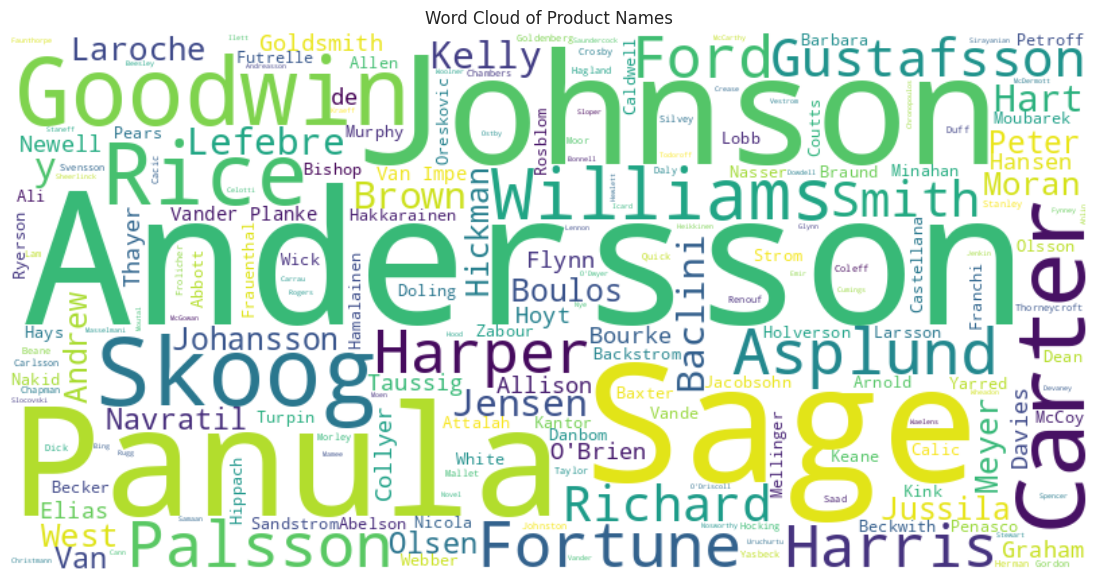

In [18]:
# ✏️ Your code here
from wordcloud import WordCloud, STOPWORDS

df['first_name'] = df['name'].apply(lambda name: name.split(',')[0])

all_names = " ".join(df['first_name'].dropna())
# all_names
wordcloud = WordCloud(width=800, height=400, background_color='white', stopwords=STOPWORDS).generate(all_names)

fig, ax = plt.subplots(figsize=(14, 7))
ax.imshow(wordcloud, interpolation='bilinear')
ax.axis('off')
ax.set_title('Word Cloud of Product Names')

# # To save it
# from pathlib import Path

# # Create figures folder
# Path('figures').mkdir(exist_ok=True)

# # Save dashboard as PNG
# plt.savefig(
#     'figures/Word_Cloud_of_Product_Names.png',
#     dpi=150,
#     bbox_inches='tight'
# )

# from google.colab import files
# files.download('figures/Word_Cloud_of_Product_Names.png')

plt.show()

❓ **Question:** What do you notice about the most common words in each cloud?

✍️ **Your answer:** _..._

<a id="ch5"></a>
# 🧭 Chapter 5: Choosing the Right Chart

### 📝 Exercise 5.1: Pick the chart

For each question below, write in the table the **chart type** you would choose and **why** (think: distribution, comparison, relationship, composition, trend, interaction). Then **build any two** of them in the code cell.

| # | Question | Chart type | Why |
|---|---|---|---|
| a | How are fares distributed in Third class? | Density Plot | to show the distrebution of fare prices over all third class |
| b | Which port sent the most passengers? | bar plot | |
| c | Do older passengers pay higher fares? | scatterplot | |
| d | What share of each class survived? | bar plot | |
| e | How does survival depend on both age group and sex? | Grouped bar chart | |
| f | How does the survival rate change as family size grows? | line plot | |

_Double-click this cell to fill in the table._

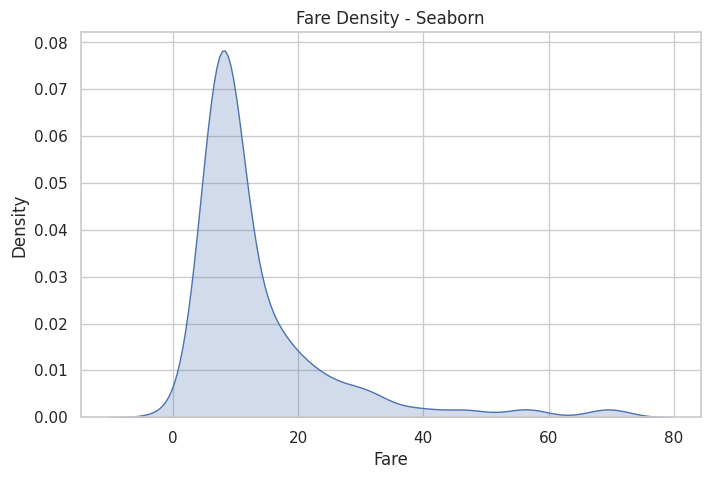

In [ ]:
# ✏️ Your code here
# A- How are fares distributed in Third class?
fig, ax = plt.subplots()

sns.kdeplot(df['fare'].where(df['pclass'] == 3), fill=True, ax=ax)
ax.set(title="Fare Density - Seaborn", xlabel="Fare")

# ax.set_xticks(np.arange(0, 81, 5))
plt.show()

Text(0, 0.5, 'Number of Passengers')

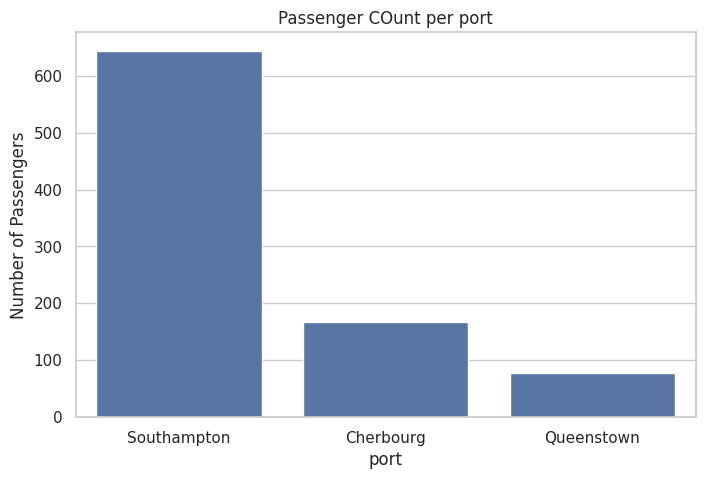

In [ ]:
# B - Which port sent the most passengers?
fig, axes = plt.subplots()

sns.countplot(data=df, x='port', order=df['port'].value_counts().index, ax=axes)

axes.set_title('Passenger COunt per port')
axes.set_xlabel('port')
axes.set_ylabel('Number of Passengers')

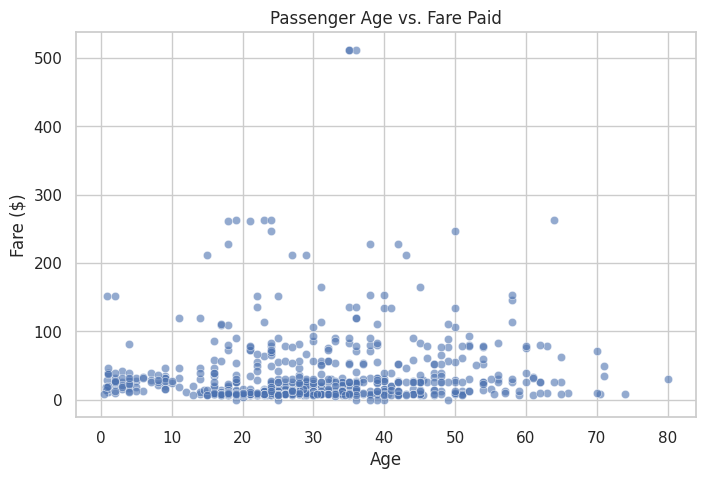

In [ ]:
# C - Do older passengers pay higher fares?

# Scatter plot to show relationship between Age and Fare
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='age', y='fare', alpha=0.6)

plt.title('Passenger Age vs. Fare Paid')
plt.xlabel('Age')
plt.ylabel('Fare ($)')

plt.show()

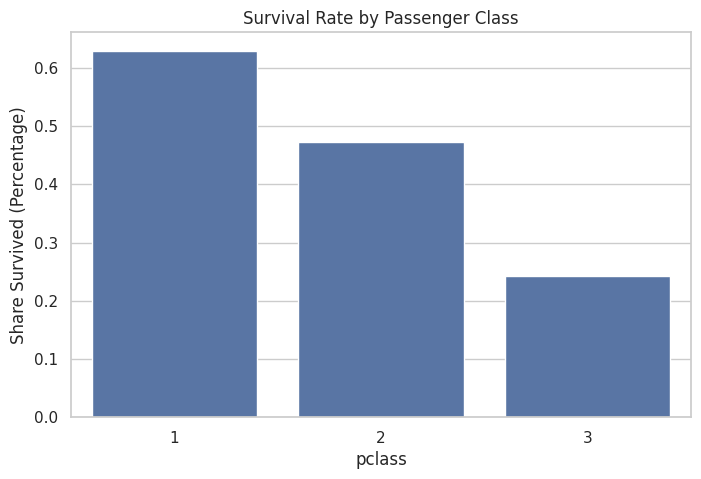

In [ ]:
sns.barplot(data=df, x='pclass', y='survived', errorbar=None)
plt.ylabel('Share Survived (Percentage)')
plt.title('Survival Rate by Passenger Class')
Survival Rate by Age Group and Sexplt.show()

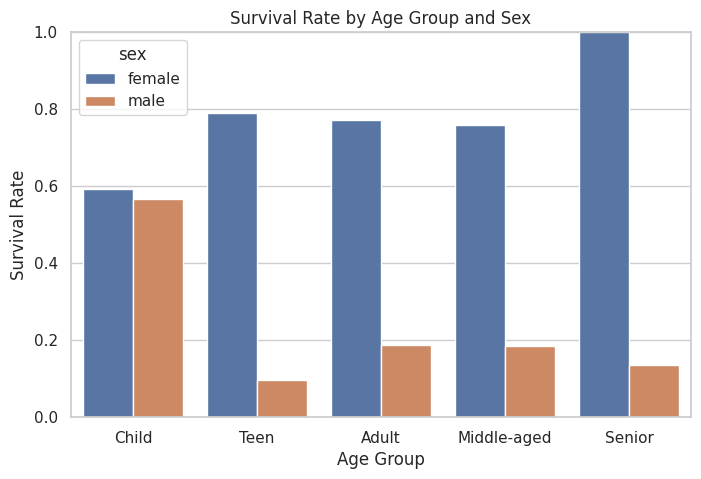

In [5]:
# Survival Rate by Age Group and Sex
# Calculate survival rate
survival_age = df.groupby(
    ['age_group', 'sex'], observed=True
)['survived'].mean().reset_index()

# Plot
sns.barplot(
    data=survival_age,
    x='age_group',
    y='survived',
    hue='sex'
)

plt.title('Survival Rate by Age Group and Sex')
plt.xlabel('Age Group')
plt.ylabel('Survival Rate')
plt.ylim(0, 1)
plt.legend(title='sex')
plt.show()

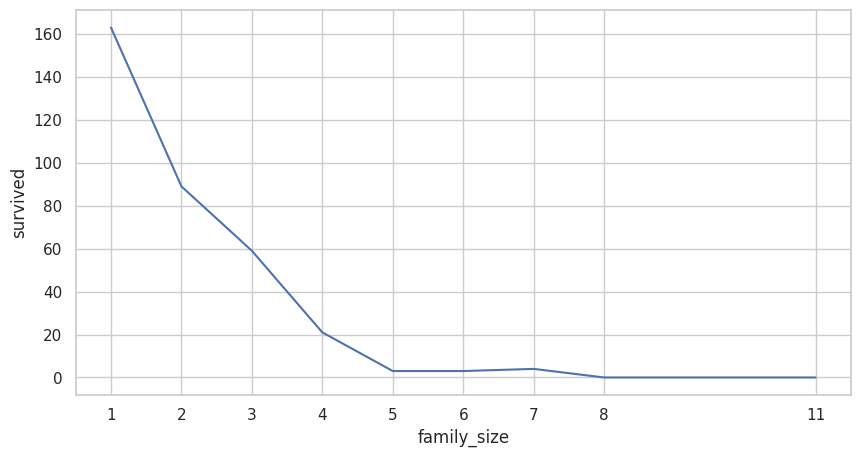

In [6]:
# survival rate change as family size grows
survival_rate = df.groupby("family_size")['survived'].sum()

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=survival_rate)
ax.set_xticks(survival_rate.index)
plt.show()

### 📝 Exercise 5.2: Fix the bad choices

Each of these charts is a poor choice. Explain **why** in the answer cell, then build a **better** version of each in the code cell.

1. A **pie chart** of `age` (each age as a slice).
2. A **line chart** of the passenger count by `port` (C, Q, S connected with a line).
3. A **scatter plot** of `sex` vs `survived`.

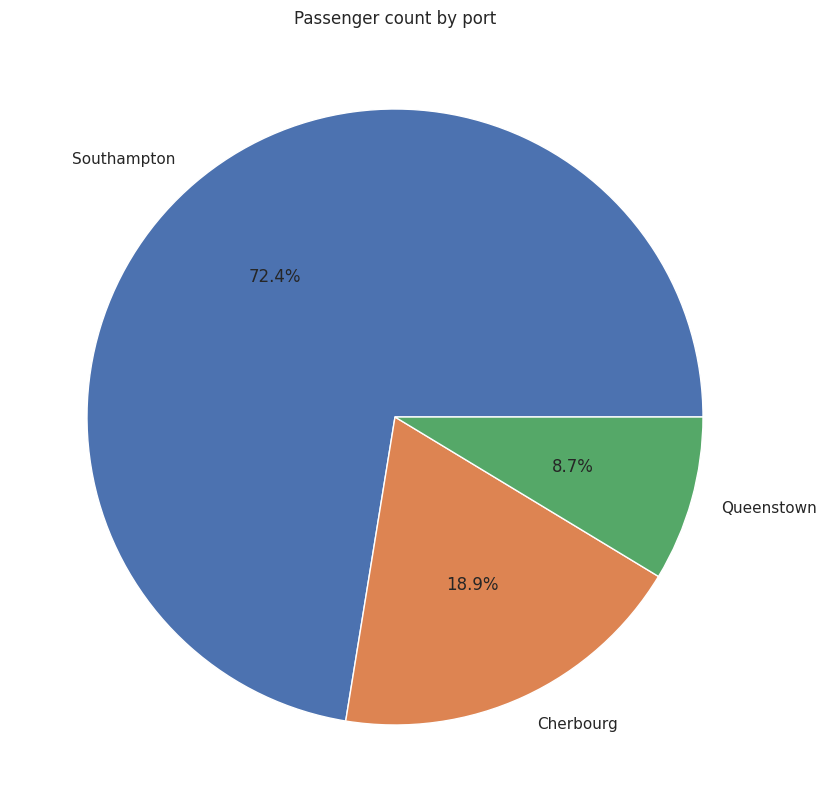

In [14]:
# ✏️ Your code here

# -------- 1 --------
# sns.histplot(data=df, x='age', bins=20)
# plt.show()

# -------- 2 --------
age_counts = df['port'].value_counts()

plt.figure(figsize=(10, 10))
plt.pie(
    age_counts,
    labels=age_counts.index,
)

plt.title('Passenger count by port')

# To save it
from pathlib import Path

# Create figures folder
Path('figures').mkdir(exist_ok=True)

# Save dashboard as PNG
plt.savefig(
    'figures/Passenger_count_by_port_pie.png',
    dpi=150,
    bbox_inches='tight'
)

from google.colab import files
files.download('figures/Passenger_count_by_port_pie.png')


plt.show()

✍️ **Your answer:** _..._

<a id="ch6"></a>
# ⚠️ Chapter 6: Misleading Charts

### 📝 Exercise 6.1: Truncated y-axis

Plot the survival rate of the 3 classes **twice**, side by side:
- an **honest** version with the y-axis starting at 0
- a **misleading** version where the y-axis starts at 0.2

(0.2, 1.0)

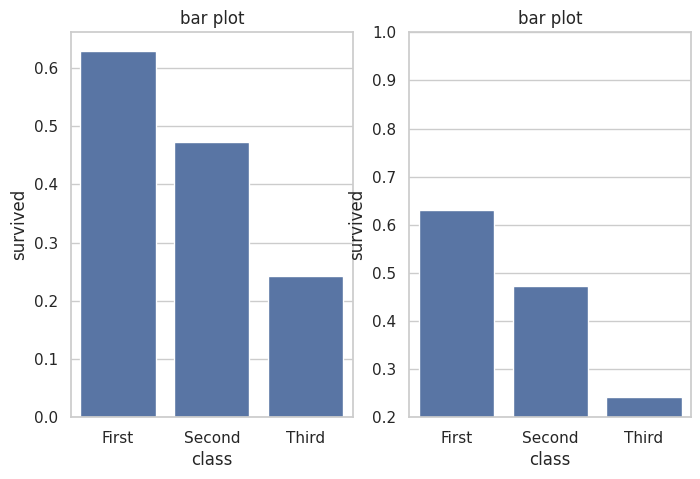

In [34]:
# ✏️ Your code here

classes = df.groupby('class')['survived'].mean()

# fig = px.bar(x=classes.index, y=classes.values, title='Top 6 Most Common Titles')
# # fig.update_yaxes(range=[0.2, None])
# fig.show()
fig, ax = plt.subplots(1, 2)

sns.barplot(classes, ax=ax[0])
ax[0].set(title="bar plot", xlabel="class")

sns.barplot(classes, ax=ax[1])
ax[1].set(title="bar plot - misleading", xlabel="class")
ax[1].set_ylim(0.2, 1)

# # ax.set_xticks(np.arange(0, 81, 5))
# plt.show()

❓ **Question:** In the misleading chart, how many times taller does the First-class bar look compared with Third? What is the real ratio of their survival rates?

✍️ **Your answer:** _..._

### 📝 Exercise 6.2: Pie chart with too many slices

Show the passenger count by `title` (all 17 titles) as a **pie chart** and as a **sorted horizontal bar chart**, side by side.

In [ ]:
# ✏️ Your code here

❓ **Question:** How many of the 17 titles can you actually read in the pie? Which chart would you put in a report?

✍️ **Your answer:** _..._

### 📝 Exercise 6.3: Hiding small samples

Plot the survival rate by `title` for **all** titles, sorted from highest to lowest. Then add the **number of passengers** for each title as a text label on each bar (or color the bars by count).

<details>
<summary>💡 Hint</summary>

`bar_label()`

</details>

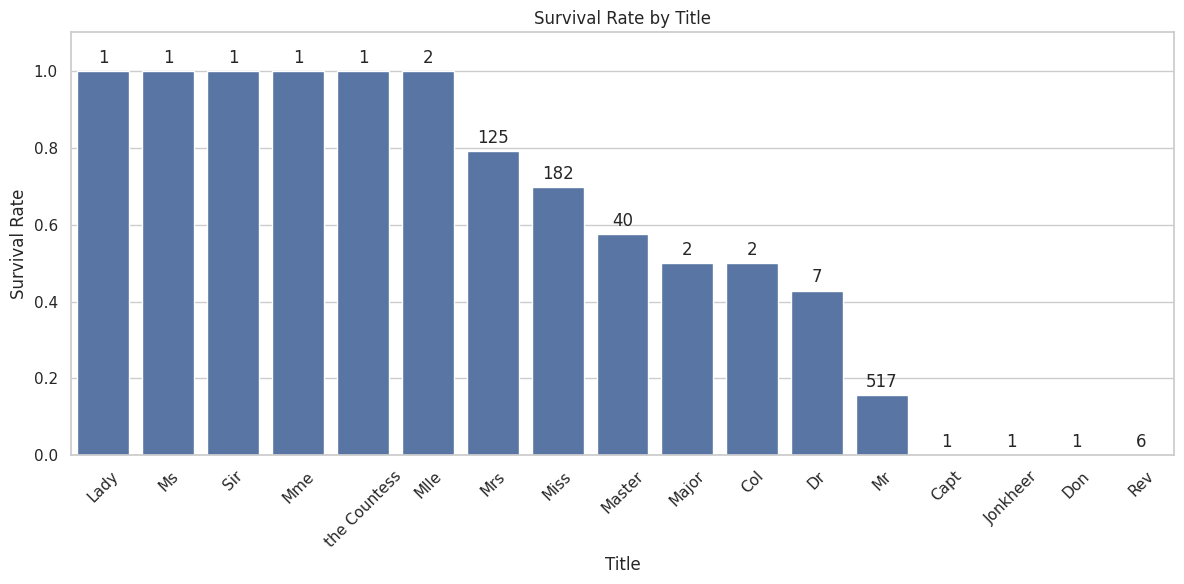

In [36]:
# ✏️ Your code here

# Calculate survival rate and passenger count per title
title_stats = df.groupby('title')['survived'].agg(
    SurvivalRate='mean',
    PassengerCount='count'
).reset_index()

# Sort from highest to lowest survival rate
title_stats = title_stats.sort_values(
    by='SurvivalRate',
    ascending=False
)

# Create bar plot
fig, ax = plt.subplots(figsize=(12, 6))

sns.barplot(
    data=title_stats,
    x='title',
    y='SurvivalRate',
    ax=ax
)

# Add passenger counts above each bar
for container in ax.containers:
    labels = title_stats['PassengerCount'].astype(str)
    ax.bar_label(container, labels=labels, padding=3)

ax.set_title('Survival Rate by Title')
ax.set_xlabel('Title')
ax.set_ylabel('Survival Rate')
ax.set_ylim(0, 1.1)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

❓ **Question:** Several titles show a 100% or 0% survival rate. Why is that misleading? What should you do with these small groups?

✍️ **Your answer:** _..._

<a id="ch7"></a>
# 💾 Chapter 7: Saving Figures

### 📝 Exercise 7.1: Save your work

1. Create a folder `figures` (inside this `Exercises` folder).
2. Save your **mini dashboard** from Exercise 4.9 as a PNG (`dpi=150`, `bbox_inches='tight'`).
3. Save your **Plotly treemap** from Exercise 4.6 as an interactive HTML file.
4. List the folder contents to confirm both files exist.

<details>
<summary>💡 Hint</summary>

Order of `savefig()` and `show()`.

</details>

<a id="ch8"></a>
# 🏁 Chapter 8: Mini-Project: Tell the Titanic Story

Imagine you must present your findings to someone who has **never seen this data**, in **5 charts or fewer**.

1. Pick the **3 to 5 charts** that best explain *who survived and why*. You can reuse or improve charts from above.
2. Make each chart presentation-ready: clear title that states the insight (e.g. *"Women were 4× more likely to survive than men"*), labeled axes, sensible colors, sorted bars, no clutter.
3. Under each chart, write a one-sentence 📌 **Insight**.
4. Finish with a short **summary** (3 to 5 bullet points) of the key findings.

In [ ]:
# ✏️ Your code here

📌 **Insight:** _..._

In [ ]:
# ✏️ Your code here

📌 **Insight:** _..._

In [ ]:
# ✏️ Your code here

📌 **Insight:** _..._

## 📌 Summary of Key Findings

- _..._
- _..._
- _..._

## 🤔 Reflection Questions

1. Which library (Matplotlib, Seaborn, Plotly) did you find easiest for each type of chart? When would you choose Plotly over Seaborn?
2. `age` is missing for about 20% of passengers. How could that bias the age-related charts? Which passengers are you not seeing?
3. Correlation (Exercise 3.7) and the faceted bar charts (Exercise 4.3) both describe survival. Which one tells you more, and why?
4. Name one chart you made that you would **not** show to a manager, and explain why.

✍️ **Your answer:** _..._